# EDA 01: Non-sports event data

**Data:** `data/processed/nonsports_events.csv`, built by `events/run_pipeline.sh`
**Scope:** 555 events at TD Garden, Wang Theatre and MGM Music Hall at Fenway, Jan 2024 – Sep 2026
**Plan:** see `eda/EDA_PLAN.md`. Figures are written to `eda/figures/`.

This notebook checks that the event table is clean and usable, shows where each field comes from, and describes event volume, timing and text coverage. It does not use any Bluebikes data.

In [1]:
from pathlib import Path
import re
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
DATA = ROOT / "data" / "processed" / "nonsports_events.csv"
FIG = ROOT / "eda" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Deck colours; venue colours validated (dataviz palette check: CVD-safe, all pairs).
NAVY, MUTED, GRID, NEUTRAL = "#0B2240", "#5b6577", "#e3e7ee", "#c9d2de"
VENUES = ["TD Garden", "Wang Theatre", "MGM Music Hall at Fenway"]
SHORT = {"TD Garden": "TD Garden", "Wang Theatre": "Wang Theatre", "MGM Music Hall at Fenway": "MGM Music Hall"}
COLOR = {"TD Garden": "#2a78d6", "Wang Theatre": "#eb6834", "MGM Music Hall at Fenway": "#1baf7a"}
REAL = "#2a78d6"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": NAVY, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "text.color": NAVY, "legend.frameon": False,
})

df = pd.read_csv(DATA, parse_dates=["date_start"])
df["venue"] = pd.Categorical(df.venue_name, VENUES, ordered=True)
df["month"] = df.date_start.dt.to_period("M")
df["quarter"] = df.date_start.dt.to_period("Q")
print(f"{len(df)} events, {df.date_start.min():%Y-%m-%d} to {df.date_start.max():%Y-%m-%d}")
df.groupby("venue", observed=True).size().rename("events").to_frame()

555 events, 2024-01-08 to 2026-09-30


,events
venue,
TD Garden,159
Wang Theatre,80
MGM Music Hall at Fenway,316


## 1. Completeness and integrity

In [2]:
required = ["event_id", "event_name", "category", "venue_name", "venue_lat", "venue_lon",
            "date_start", "date_end", "time_start", "time_end_or_duration", "description", "source_url"]
completeness = pd.DataFrame({
    "missing": df[required].isna().sum(),
    "pct_complete": (1 - df[required].isna().mean()).mul(100).round(1),
})
print("duplicate event_id:", df.event_id.duplicated().sum())
print("duplicate venue+date:", df.duplicated(["venue_name", "date_start"]).sum())
completeness

duplicate event_id: 0
duplicate venue+date: 0


,missing,pct_complete
event_id,0,100.0
event_name,0,100.0
category,0,100.0
venue_name,0,100.0
venue_lat,0,100.0
venue_lon,0,100.0
date_start,0,100.0
date_end,0,100.0
time_start,0,100.0
time_end_or_duration,0,100.0


In [3]:
# Leakage check: every real description must be dated before its event day.
real = df[df.has_real_text].copy()
real["text_date"] = pd.to_datetime(real.description_timestamp.str[:10])
real["lead_days"] = (real.date_start - real.text_date).dt.days
print("real descriptions dated on/after their event:", (real.lead_days < 1).sum())

real descriptions dated on/after their event: 0


## 2. Provenance: where each field comes from

In [4]:
prov_text = pd.crosstab(df.venue, df.description_source, margins=True, margins_name="All")
prov_time = pd.crosstab(df.venue, df.time_start_source, margins=True, margins_name="All")
display(prov_text)
display(prov_time)

description_source,template,vanyaland,venue_archive,All
venue,,,,
TD Garden,15,0,144,159
Wang Theatre,9,0,71,80
MGM Music Hall at Fenway,244,72,0,316
All,268,72,215,555


time_start_source,do617_listing,venue_default,venue_page_schema,All
venue,,,,
TD Garden,9,0,150,159
Wang Theatre,37,3,40,80
MGM Music Hall at Fenway,309,7,0,316
All,355,10,190,555


## 3. Real description text by venue

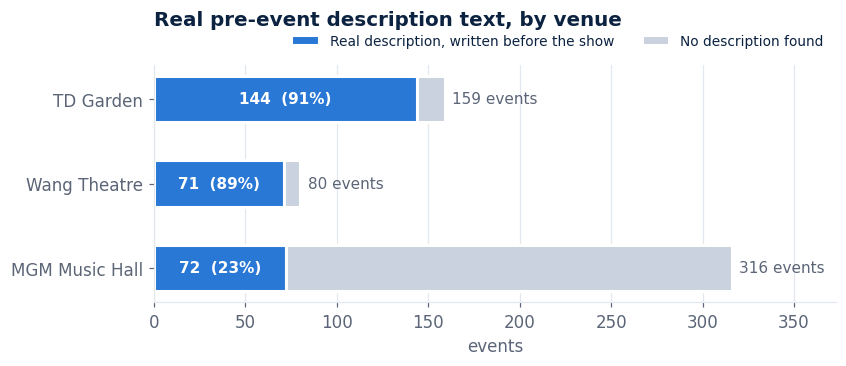

,real,total,template,real_pct
venue,,,,
MGM Music Hall at Fenway,72,316,244,0.23
Wang Theatre,71,80,9,0.89
TD Garden,144,159,15,0.91


In [5]:
counts = df.groupby("venue", observed=True).has_real_text.agg(real="sum", total="size")
counts["template"] = counts.total - counts.real
counts = counts.loc[VENUES[::-1]]

fig, ax = plt.subplots(figsize=(8, 2.8))
y = np.arange(len(counts))
ax.barh(y, counts.real, color=REAL, height=0.55, edgecolor="white", linewidth=2, label="Real description, written before the show")
ax.barh(y, counts.template, left=counts.real, color=NEUTRAL, height=0.55, edgecolor="white", linewidth=2,
        label="No description found")
for i, (venue, r) in enumerate(counts.iterrows()):
    ax.text(r.real / 2, i, f"{r.real}  ({r.real / r.total:.0%})", va="center", ha="center", color="white", fontsize=10, weight="bold")
    ax.text(r.total + 4, i, f"{r.total} events", va="center", color=MUTED, fontsize=10)
ax.set_yticks(y, [SHORT[v] for v in counts.index])
ax.set_xlabel("events")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.total.max() * 1.18)
ax.legend(loc="lower right", ncol=2, fontsize=9, bbox_to_anchor=(1, 1.02))
ax.set_title("Real pre-event description text, by venue", pad=26)
fig.savefig(FIG / "fig_text_coverage_by_venue.png")
plt.show()
counts.assign(real_pct=(counts.real / counts.total).round(2))

## 4. How far ahead of the event was the text published?

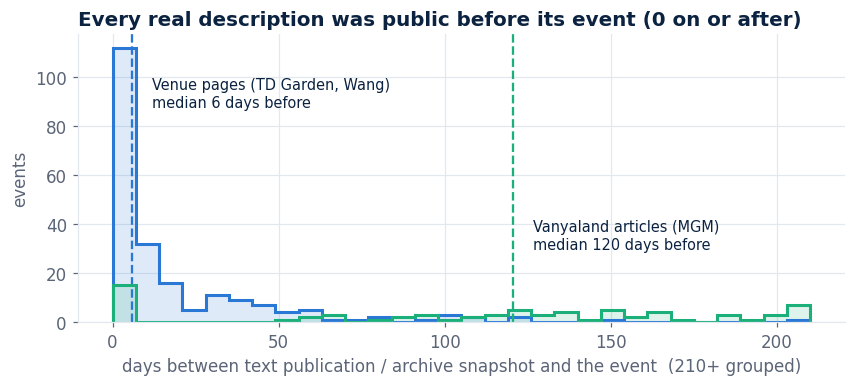

,count,min,25%,50%,75%,max
venue,,,,,,
TD Garden,144.0,1.0,3.0,6.0,19.0,284.0
Wang Theatre,71.0,1.0,2.0,6.0,29.0,148.0
MGM Music Hall at Fenway,72.0,1.0,66.0,120.0,163.0,275.0


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.arange(0, 211, 7)
for src, label, c in [("venue_archive", "Venue pages (TD Garden, Wang)", REAL), ("vanyaland", "Vanyaland articles (MGM)", "#1baf7a")]:
    d = real[real.description_source == src].lead_days
    ax.hist(d.clip(upper=209), bins=bins, histtype="step", linewidth=2, color=c)
    ax.hist(d.clip(upper=209), bins=bins, color=c, alpha=0.15)
    med = d.median()
    ax.axvline(med, color=c, linewidth=1.5, linestyle="--")
    ax.text(med + 6, {"venue_archive": 88, "vanyaland": 30}[src], f"{label}\nmedian {med:.0f} days before", color=NAVY, fontsize=9.5)
ax.set_xlabel("days between text publication / archive snapshot and the event  (210+ grouped)")
ax.set_ylabel("events")
ax.set_title("Every real description was public before its event (0 on or after)")
fig.savefig(FIG / "fig_text_lead_time.png")
plt.show()
real.groupby("venue", observed=True).lead_days.describe(percentiles=[.25, .5, .75])[["count", "min", "25%", "50%", "75%", "max"]].round(0)

## 5. Event volume over time

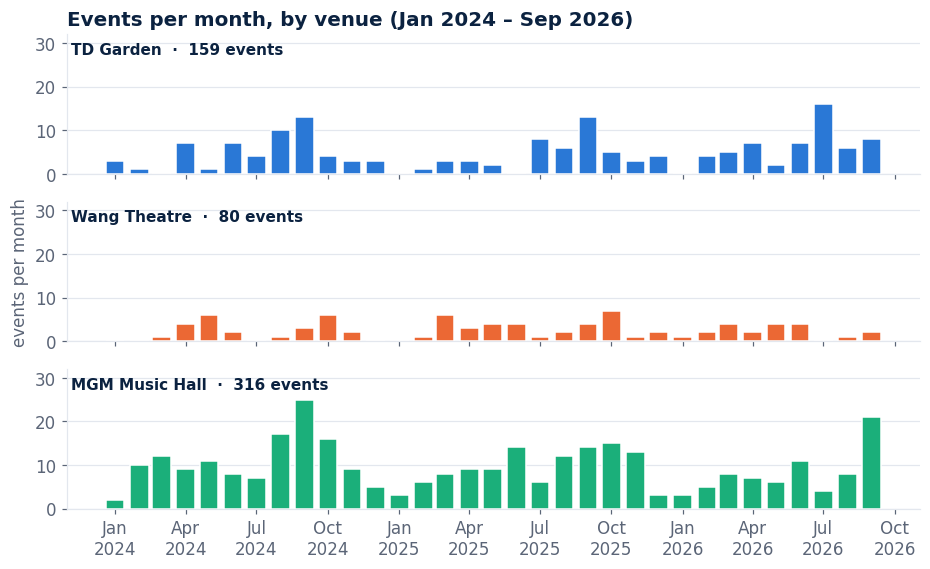

In [7]:
months = pd.period_range(df.month.min(), df.month.max(), freq="M")
fig, axes = plt.subplots(3, 1, figsize=(10, 5.6), sharex=True, sharey=True)
axes[0].set_ylim(0, 32)
for ax, venue in zip(axes, VENUES):
    s = df[df.venue == venue].groupby("month").size().reindex(months, fill_value=0)
    ax.bar(s.index.to_timestamp(), s.values, width=24, color=COLOR[venue], edgecolor="white", linewidth=1)
    ax.text(0.005, 0.86, f"{SHORT[venue]}  ·  {s.sum()} events", transform=ax.transAxes, color=NAVY, weight="bold", fontsize=10)
    ax.grid(axis="x", visible=False)
axes[1].set_ylabel("events per month")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[0].set_title("Events per month, by venue (Jan 2024 – Sep 2026)")
fig.savefig(FIG / "fig_events_per_month.png")
plt.show()

## 6. Does real-text coverage change over time?

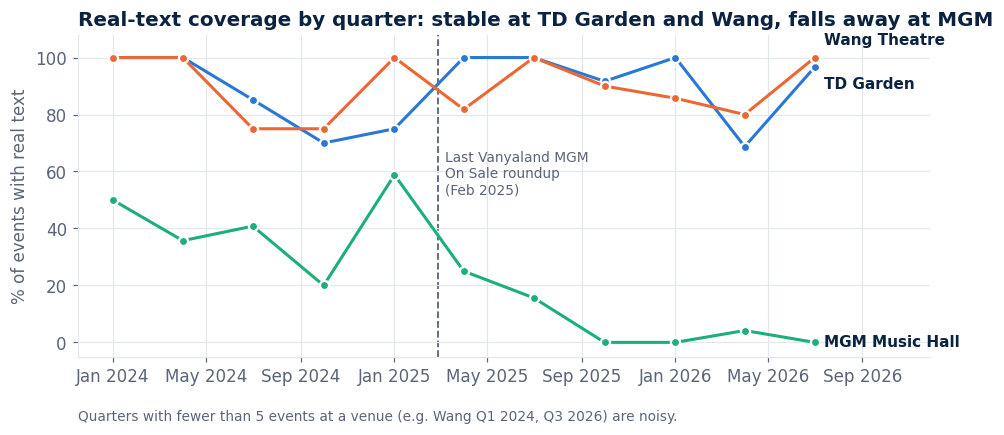

quarter,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
venue,,,,,,,,,,,
TD Garden,4,15,27,10,4,5,27,12,9,16,30
Wang Theatre,1,12,4,8,7,11,7,10,7,10,3
MGM Music Hall at Fenway,24,28,49,30,17,32,32,31,16,24,33


In [8]:
q = (df.groupby(["venue", "quarter"], observed=True).has_real_text.agg(share="mean", n="size").reset_index())
fig, ax = plt.subplots(figsize=(10, 3.8))
for venue in VENUES:
    s = q[q.venue == venue]
    x = s.quarter.dt.to_timestamp()
    ax.plot(x, s.share * 100, color=COLOR[venue], linewidth=2, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=1.5)
    nudge = {"TD Garden": -6, "Wang Theatre": 6, "MGM Music Hall at Fenway": 0}[venue]
    ax.text(x.iloc[-1] + pd.Timedelta(days=12), s.share.iloc[-1] * 100 + nudge, SHORT[venue], color=NAVY,
            va="center", fontsize=10, weight="bold")
LAST_ROUNDUP = pd.Timestamp("2025-02-27")  # last Vanyaland "On Sale: MGM Music Hall" post in the data
ax.axvline(LAST_ROUNDUP, color=MUTED, linestyle="--", linewidth=1.2, zorder=0)
ax.text(LAST_ROUNDUP + pd.Timedelta(days=8), 52, "Last Vanyaland MGM\nOn Sale roundup\n(Feb 2025)", color=MUTED, fontsize=9)
ax.set_ylim(-5, 108)
ax.set_ylabel("% of events with real text")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_xlim(right=q.quarter.max().to_timestamp() + pd.Timedelta(days=150))
ax.set_title("Real-text coverage by quarter: stable at TD Garden and Wang, falls away at MGM")
ax.text(0, -0.2, "Quarters with fewer than 5 events at a venue (e.g. Wang Q1 2024, Q3 2026) are noisy.", transform=ax.transAxes, color=MUTED, fontsize=9)
fig.savefig(FIG / "fig_text_coverage_over_time.png")
plt.show()
q.pivot(index="quarter", columns="venue", values="n").fillna(0).astype(int).T

## 7. When do events happen?

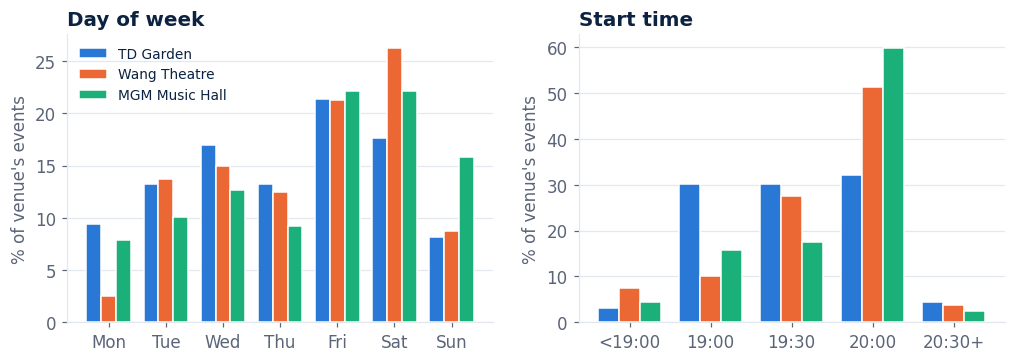

share of events starting 19:00–20:30: 95%


In [9]:
dow_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["dow"] = pd.Categorical(df.date_start.dt.strftime("%a"), dow_order, ordered=True)
df["start_hour"] = df.time_start.str[:2].astype(int) + df.time_start.str[3:5].astype(int) / 60

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
dow = pd.crosstab(df.dow, df.venue, normalize="columns") * 100
w = 0.26
for i, venue in enumerate(VENUES):
    a1.bar(np.arange(7) + (i - 1) * w, dow[venue], width=w, color=COLOR[venue], edgecolor="white", linewidth=1, label=SHORT[venue])
a1.set_xticks(np.arange(7), dow_order)
a1.set_ylabel("% of venue's events")
a1.grid(axis="x", visible=False)
a1.set_title("Day of week")
a1.legend(fontsize=9, loc="upper left")
slots = pd.cut(df.start_hour, [0, 18.99, 19.49, 19.99, 20.49, 24], labels=["<19:00", "19:00", "19:30", "20:00", "20:30+"])
st = pd.crosstab(slots, df.venue, normalize="columns") * 100
for i, venue in enumerate(VENUES):
    a2.bar(np.arange(len(st)) + (i - 1) * w, st[venue], width=w, color=COLOR[venue], edgecolor="white", linewidth=1, label=SHORT[venue])
a2.set_xticks(np.arange(len(st)), st.index)
a2.set_ylabel("% of venue's events")
a2.grid(axis="x", visible=False)
a2.set_title("Start time")
fig.savefig(FIG / "fig_event_timing.png")
plt.show()
print("share of events starting 19:00–20:30:", f"{df.start_hour.between(19, 20.5).mean():.0%}")

## 8. What is the text like?

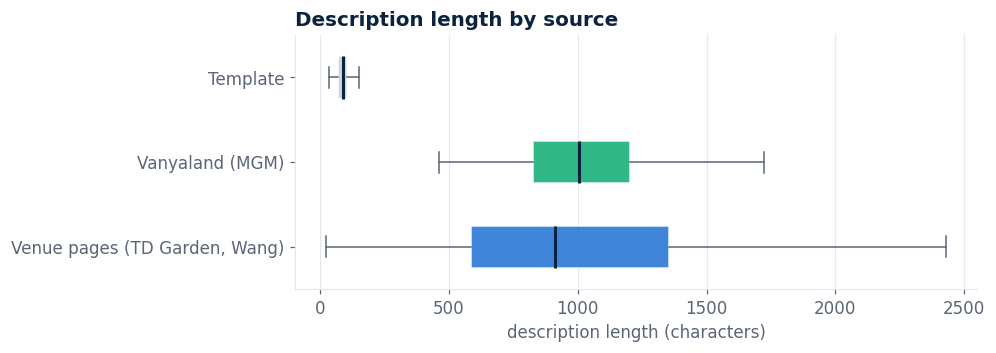

,count,25%,50%,75%
venue_archive,215.0,588.0,911.0,1353.0
vanyaland,72.0,828.0,1007.0,1204.0
template,268.0,71.0,88.0,105.0


In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
groups = [("venue_archive", "Venue pages (TD Garden, Wang)"), ("vanyaland", "Vanyaland (MGM)"), ("template", "Template")]
data = [df[df.description_source == g].description_length for g, _ in groups]
bp = ax.boxplot(data, vert=False, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=NAVY, linewidth=2), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, c in zip(bp["boxes"], [REAL, "#1baf7a", NEUTRAL]):
    patch.set(facecolor=c, edgecolor="white", alpha=0.9)
ax.set_yticks([1, 2, 3], [label for _, label in groups])
ax.set_xlabel("description length (characters)")
ax.grid(axis="y", visible=False)
ax.set_title("Description length by source")
fig.savefig(FIG / "fig_text_length.png")
plt.show()
pd.DataFrame({g: d.describe()[["count", "25%", "50%", "75%"]] for (g, _), d in zip(groups, data)}).T.round(0)

In [11]:
# Demand phrases ("sold out", "added a second show") in real text.
display(df[df.has_real_text].groupby("venue", observed=True).demand_language.agg(events="sum", share="mean").round(2))

# Most frequent content words per venue (real text only), a quick look at what TF-IDF will see.
STOP = set('''a an the and or of to in on at for with by from is are was were be been this that it its as their his her
his they he she we you your our will has have had not but all more new also into after over than who which when where
tour show shows boston ma garden td wang theatre mgm music hall fenway tickets ticket on-sale sale presale available
date dates night live one two first year years time album world north america american including us part best
like out what about just now there can so up if how get back some even them through way only most just make
'''.split())
def top_words(texts, n=12):
    words = Counter(w for t in texts for w in re.findall(r"[a-z][a-z'-]{2,}", t.lower()) if w not in STOP)
    return ", ".join(w for w, _ in words.most_common(n))
pd.DataFrame({SHORT[v]: [top_words(df[(df.venue == v) & df.has_real_text].description)] for v in VENUES}, index=["top words"]).T

,events,share
venue,,
TD Garden,44,0.31
Wang Theatre,8,0.11
MGM Music Hall at Fenway,5,0.07


,top words
TD Garden,"announced, across, global, grammy, fans, speci..."
Wang Theatre,"award, band, released, songs, grammy, artist, ..."
MGM Music Hall,"band, because, love, off, record, last, march,..."


## 9. Key numbers for the slides

In [12]:
r = df.has_real_text
summary = {
    "events": len(df),
    "venues": df.venue_name.nunique(),
    "window": f"{df.date_start.min():%b %Y} – {df.date_start.max():%b %Y}",
    "events with real pre-event text": f"{r.sum()} ({r.mean():.0%})",
    "real text, TD Garden / Wang / MGM": " / ".join(f"{df[df.venue == v].has_real_text.mean():.0%}" for v in VENUES),
    "start time from a real listing": f"{(~df.time_assumed).mean():.0%}",
    "median days text precedes event": f"{real.lead_days.median():.0f}",
    "text dated on/after its event (leakage)": int((real.lead_days < 1).sum()),
    "categories": df.category.value_counts().to_dict(),
    "real descriptions with demand phrases": f"{df[r].demand_language.sum()} ({df[r].demand_language.mean():.0%})",
}
pd.Series(summary, name="value").to_frame()

,value
events,555
venues,3
window,Jan 2024 – Sep 2026
events with real pre-event text,287 (52%)
"real text, TD Garden / Wang / MGM",91% / 89% / 23%
start time from a real listing,98%
median days text precedes event,8
text dated on/after its event (leakage),0
categories,"{'concert': 541, 'comedy': 13, 'dance_theater'..."
real descriptions with demand phrases,57 (20%)


## Findings

**Data quality (slide 1)**
- 555 events (TD Garden 159, Wang Theatre 80, MGM Music Hall 316), Jan 2024 – Sep 2026. All 12 shared-schema fields are 100% complete; no duplicate event IDs or venue-dates.
- **No leakage:** 0 of 287 real descriptions are dated on or after their event.
- **Provenance:** text comes from archived venue pages (215 events) or Vanyaland (72); 268 events fall back to a template. Start times come from real listings for 98% (venue JSON-LD 190, Do617 355); only 10 use a venue default.

**Text coverage (slides 1–2)**
- Real text: TD Garden **91%**, Wang **89%**, MGM **23%** (52% overall).
- Coverage is **stable over time** at TD Garden and Wang (69–100% per quarter) but **falls to about 0% at MGM by late 2025**. Vanyaland's last MGM On Sale roundup was in Feb 2025; because roundups previewed shows months ahead, MGM coverage fades through mid-2025 and is 0–4% from Q4 2025. A time-based test set in 2026 will contain almost no MGM real-text events, so the text comparison will rest on TD Garden and Wang.
- **Text timing differs by source:** venue-page snapshots are a median of 6 days before the event; Vanyaland articles a median of 120 days (written at announcement). Venue-page text therefore often includes late updates ("second show added"): 31% of TD Garden descriptions have demand phrases vs 11% Wang and 7% MGM. This is legitimate pre-event information but motivates the `demand_language` robustness check.
- Real descriptions are long (median about 900–1,000 characters) versus about 90 for templates, so text features will separate the two groups easily. `description_source` must be a feature in every configuration.

**Event timing (slide 2)**
- Events cluster on **Fri–Sat** (39–48% of each venue's events) and start between **19:00 and 20:30 (95%)**. MGM and Wang mostly start at 20:00; TD Garden is spread across 19:00–20:00.
- So event windows (−3 h before start to +2 h after estimated end) fall mostly between about 16:00 and midnight, the same evening hours where the pilot found the Fenway game-day spike.
- Volume peaks in late summer/early autumn at TD Garden and MGM; Wang is steadier and smaller (about 2–4 events/month).